In [1]:
# general imports
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
# mask-analog imports
import run_experiments as rexp
import plot_analogs as pa
import best_analogs as ba
# hide some warnings that are not helpful
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
# make plots show up in the notebook?
%matplotlib inline

# workflow for a new experiment

this is a simplified version of the tutorial that uses functions to bypass running every step

### 1. create a dictionary entry for the new experiment

In [2]:
# first, create an Experiments object which allows you to define a new experiment and run it
# the json file it is referencing saves all of your experiments in a file, so they can be run, re-run, referenced, etc.
exp_object = rexp.Experiments('experiments.json')
# print out the settings
# print(exp_object.make_exp_dictionary.__doc__)
# print('---------------------------------------------------------')
# # these are all the available models and variables in the raw_data directory
# # the number of members is also shown, along with the resolution
# print(exp_object.list_variables)
# print('---------------------------------------------------------')
# # this lists all the regions available (you can add new regions to regions.json)
# print(exp_object.list_regions)

In [48]:
experiment_name = 'new_dict_test'

In [44]:
# now, define a new experiment with all the settings you want to change
new_exp = exp_object.make_exp_dictionary(experiment_name, variable_list=['tas',], analog_models=["CESM2", "MIROC-ES2L", "MPI-ESM1-2-LR"], soi_models=["BEST"], leadtime=1, split=[3, 1, 1], region='western us', val_models=["ERA5"], prediction_nodes=[5, 5, 5], prediction_activation='elu', learning_rate=0.001, method='jacob', mask=False, output_period='1Y', roll_period=False, window=False, resolutions=[2.7672718509152787, 2.8125], season=False, time_range=None, norm_data=True, baseline=[1961, 1990], remove_trend=False, remove_seasonality=False, loss='mse', patience=50, min_delta=0.0005, batch_size=64, val_batch_size=2500, max_epochs=5000, mask_activation='relu', mask_init="test", mask_l1=0.001, mask_l2=0.0, norm_weights=True, seed=20)

# this adds the experiment to the json file
exp_object.add_experiment(new_exp)

# # now, define a new experiment with all the settings you want to change
# new_exp = exp_object.make_exp_dictionary(experiment_name, variable_list=['tas',], analog_models=["CESM2", "MIROC-ES2L", "MPI-ESM1-2-LR"], soi_models=["CESM2", "MIROC-ES2L", "MPI-ESM1-2-LR"], leadtime=5, split=[5, 3, 2], region='western us', prediction_nodes=[5, 5, 5], prediction_activation='elu', learning_rate=0.001, method='jacob', mask=False, output_period='1Y', data_period='monthly', roll_period=False, window=False, resolutions=[2.7672718509152787, 2.8125], season=False, time_range=None, norm_data=True, baseline=[1961, 1990], remove_trend=False, remove_seasonality=False, loss='mse', patience=50, min_delta=0.0005, batch_size=64, val_batch_size=2500, max_epochs=5000, mask_activation='relu', mask_init="ones", mask_l1=0.0, mask_l2=0.0, norm_weights=True, seed=20)
# # this adds the experiment to the json file
# exp_object.add_experiment(new_exp)

experiment_settings are:
{'new_dict_test2': {'experiment_name': 'new_dict_test2', 'variable_list': ['tas'], 'analog_models': ['CESM2', 'MIROC-ES2L', 'MPI-ESM1-2-LR'], 'soi_models': ['BEST'], 'leadtime': 1, 'split': {'analog': 3, 'training': 1, 'validation': 1}, 'region': 'western us', 'val_models': ['ERA5'], 'prediction_nodes': [5, 5, 5], 'prediction_activation': 'elu', 'learning_rate': 0.001, 'method': 'jacob', 'mask': False, 'output_period': '1Y', 'roll_period': False, 'window': False, 'resolutions': [2.7672718509152787, 2.8125], 'season': False, 'time_range': None, 'norm_data': True, 'baseline': [1961, 1990], 'remove_trend': False, 'remove_seasonality': False, 'loss': 'mse', 'patience': 50, 'min_delta': 0.0005, 'batch_size': 64, 'val_batch_size': 2500, 'max_epochs': 5000, 'mask_activation': 'relu', 'mask_init': 'test', 'mask_l1': 0.001, 'mask_l2': 0.0, 'norm_weights': True, 'seed': 20, 'avg_target': False, 'inputs_proc_steps': ["smooth_time(period=experiment_settings['output_period'

In [43]:
exp_object.delete_experiment(experiment_name)

### 2. make the mask

In [45]:
# NOTE: this may need to be run in a terminal when the amount of data is large
exp_object.make_mask(experiment_name, transfer=['test', 20], overwrite_model=True, overwrite_mask=True)

loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (1467, 65, 128, 1) and (1467, 7, 5, 1)
input and target datasets reshaped to (173, 65, 128, 1) and (173, 7, 5, 1)
input and target datasets reshaped to (82, 65, 128, 1) and (82, 7, 5, 1)
----------------------------------------------------------------
Epoch 1/5000
2/2 [==============================] - 0s 179ms/step - loss: 13.0801 - pred_range: 4.8000 - val_loss: 11.7783 - val_pred_range: 2.8583
Epoch 2/5000
2/2 [==============================] - 0s 100ms/step - loss: 12.9477 - pred_range: 5.1982 - val_loss: 11.7782 - val_pred_range: 2.8721
Epoch 3/5000
2/2 [==============================] - 0s 101ms/step - loss: 11.1729 - pred_range: 4.1898 - val_loss: 11.7782 - val_pred_range: 2.8788
Epoch 4/5000
2/2 [==============================] - 0s 100ms/step - loss: 11.0997 - pred_range: 

<xarray.Dataset>
Dimensions:  (lat: 65, lon: 128)
Coordinates:
  * lat      (lat) float32 -88.62 -85.85 -83.08 -80.31 ... 82.95 85.72 88.49
  * lon      (lon) float32 0.0 2.812 5.625 8.438 ... 348.8 351.6 354.4 357.2
Data variables:
    tas      (lat, lon) float32 0.1756 0.1757 0.1765 ... 0.05722 0.05773 0.05807

loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (1467, 65, 128, 1) and (1467, 7, 5, 1)
input and target datasets reshaped to (82, 65, 128, 1) and (82, 7, 5, 1)
input and target datasets reshaped to (173, 65, 128, 1) and (173, 7, 5, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


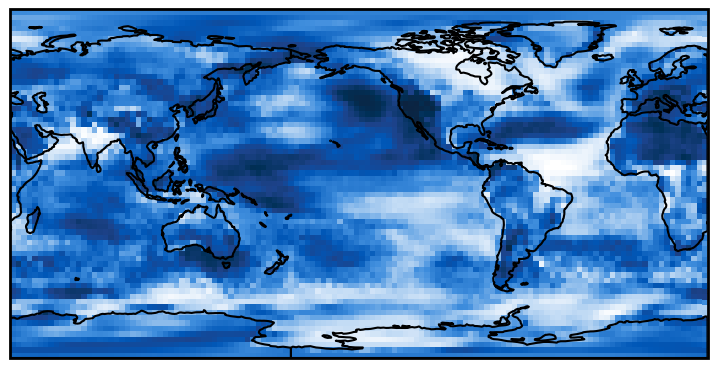

In [49]:
# plot the mask
exp_object.plot_mask(experiment_name, colorbar=False)
# exp_object.make_mask_gif(experiment_name)

loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (1467, 65, 128, 1) and (1467, 7, 5, 1)
input and target datasets reshaped to (173, 65, 128, 1) and (173, 7, 5, 1)
input and target datasets reshaped to (82, 65, 128, 1) and (82, 7, 5, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


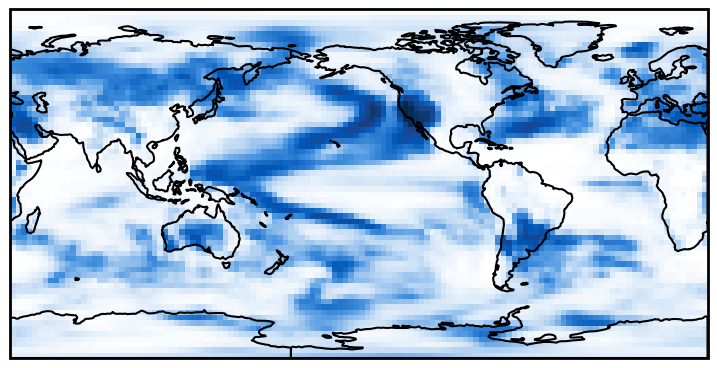

In [47]:
exp_object.plot_mask(experiment_name, colorbar=False)

### 3. generate a library of analogs and SOIs (states of interest)

now that the mask has been calculated, we can make regular analog forecasts using the mask

to do this, we need to generate a library of potential analogs that can be matched to our state of interest (the SOIs go in the same library)

In [32]:
# model_list is to set the models in the library, n_members sets how many (-1 uses all)
experiment_name = 'test5lt'
library = ba.BestAnalogs(experiment_name, model_list=["CESM2", "MIROC-ES2L", "MPI-ESM1-2-LR", "ERA5"], n_members=-1)

loading all available members, using 5 members from model: CESM2
loading variables: tas
from models: CESM2
successfully loaded 5 ensemble members from /Users/mafern/Desktop/mask-analog-projections/raw_data/monthly/CESM2/tas
#################################################################
processing CESM2 input dataset
#################################################################
down-sampling dataset from 1M to 1Y
time period is now 1Y with 251 time steps
-------------------------------------------------------
regridding datasets to resolution [2.7672718509152787, 2.8125]
-------------------------------------------------------
baselining on [1961, 1990] for variables: tas
-------------------------------------------------------
-------------------------------------------------------
#################################################################
processing CESM2 target dataset
#################################################################
down-sampling dataset from 1M to 1Y
ti

### 4. calculate the best analogs for a given SOI

In [36]:
# this ranks the analogs in the library for this SOI (in this case member 0 of BEST)
# this may also need to be run in the terminal
import importlib as imp
import best_analogs as ba
imp.reload(ba)
experiment_name = 'test5lt'
library = ba.BestAnalogs(experiment_name)
for tether in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]:
    library.get_all_soi_analogs("ERA5", 0, tether=tether, savename='ERA5_mem0_teth'+str(tether)+'_inv2')
    # library.get_all_soi_analogs("ERA5", 0, tether=tether, savename='ERA5_mem0_teth'+str(tether)+'_inv')
    # library.get_all_soi_analogs("ERA5", 0, tether=tether)

previously saved analogs: ERA5_mem0_teth1 ERA5_mem0_teth10 ERA5_mem0_teth10_inv ERA5_mem0_teth1_inv ERA5_mem0_teth2 ERA5_mem0_teth2_inv ERA5_mem0_teth3 ERA5_mem0_teth3_inv ERA5_mem0_teth4 ERA5_mem0_teth4_inv ERA5_mem0_teth5 ERA5_mem0_teth5_inv ERA5_mem0_teth6 ERA5_mem0_teth6_inv ERA5_mem0_teth7 ERA5_mem0_teth7_inv ERA5_mem0_teth8 ERA5_mem0_teth8_inv ERA5_mem0_teth9 ERA5_mem0_teth9_inv multimask_test multimask_test_inv
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/test5lt/ERA5_mem0_teth1_inv2.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/test5lt/ERA5_mem0_teth2_inv2.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/test5lt/ERA5_mem0_teth3_inv2.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/test5lt/ERA5_mem0_teth4_inv2.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/test5lt/ERA5_mem0_teth5_inv2.pickle
saving to: /Users/mafern/Desktop/mask-analo

### 5. analysis and plots

once the above has been run, the library now contains inputs, targets, and indices (indices are added for each SOI)

In [653]:
# suite of plots
library = pa.PlotAnalogs(experiment_name, "ERA5", 0, 9, 'tas')

previously saved analogs: ERA5_mem0_teth2 ERA5_mem0_teth10 ERA5_mem0_teth8 ERA5_mem0_teth4 ERA5_mem0_teth6 ERA5_mem0_teth3 ERA5_mem0_teth1 ERA5_mem0_teth9 ERA5_mem0_teth5 ERA5_mem0_teth7
loaded analogs for ERA5_mem0_teth9


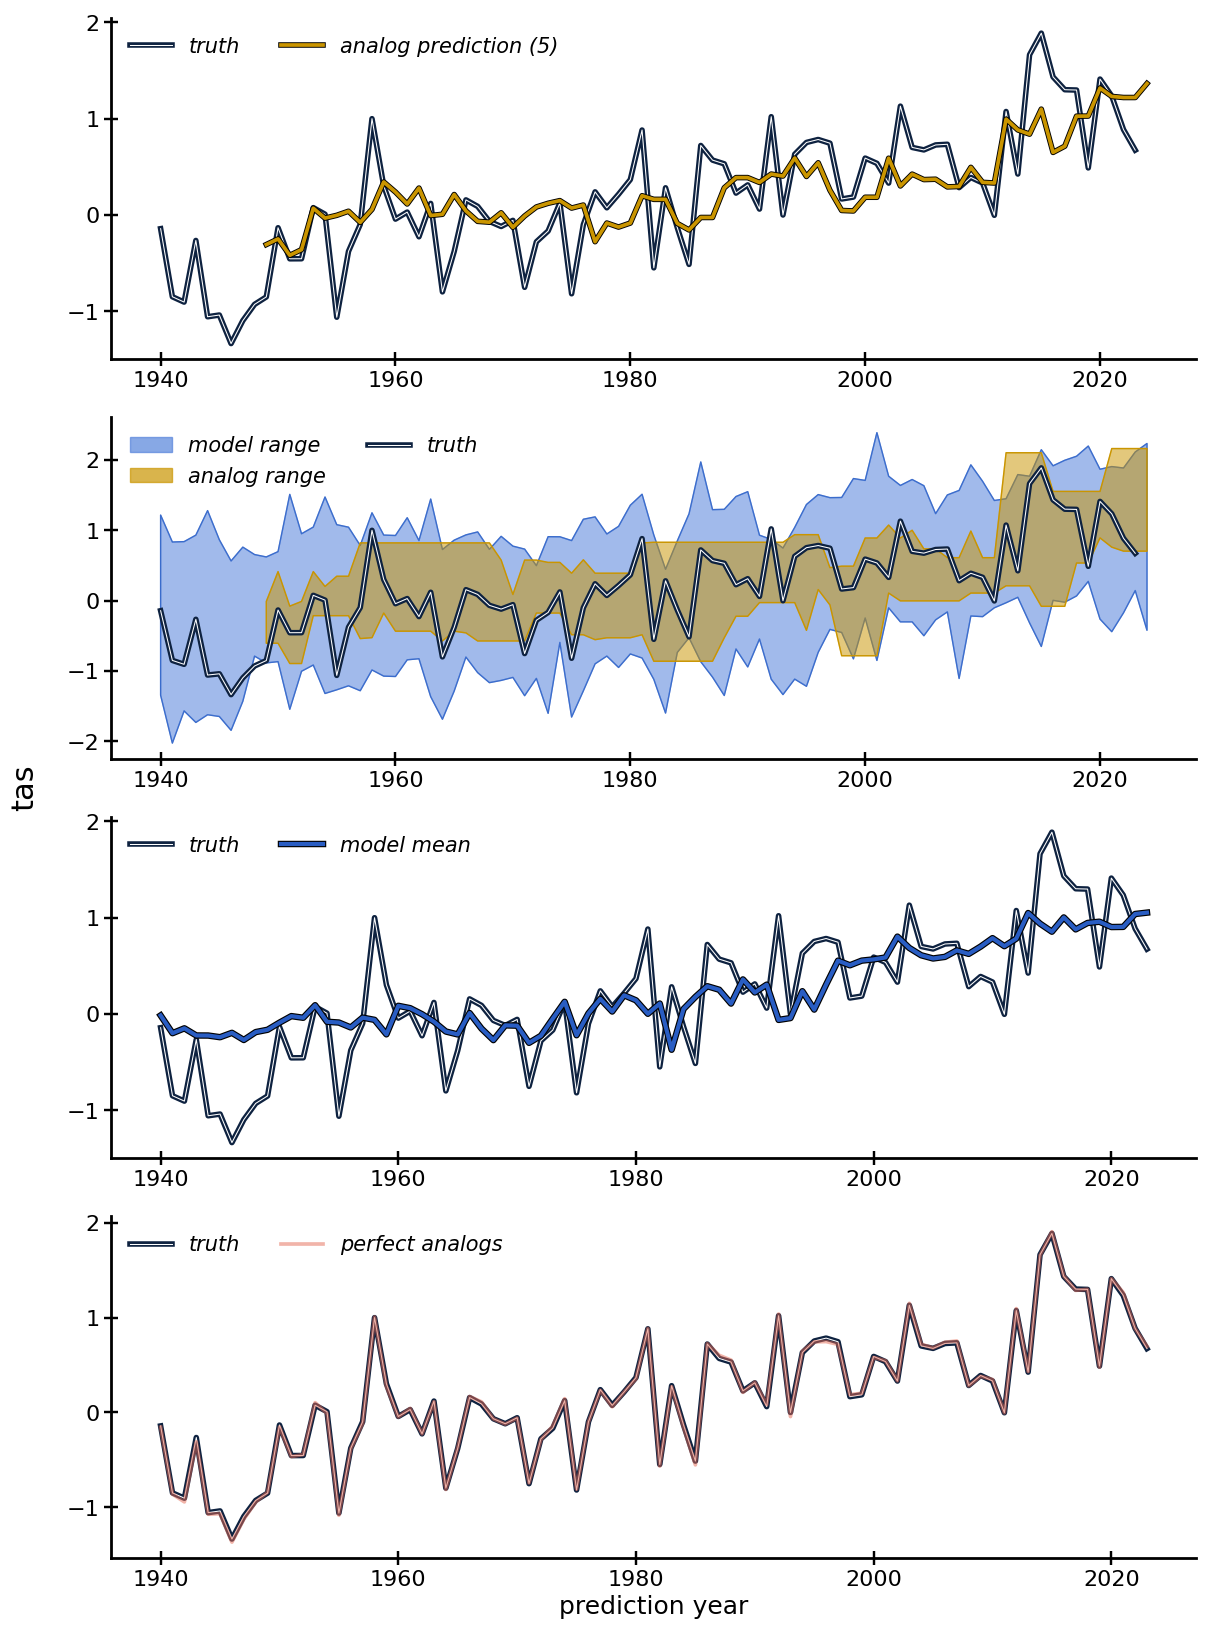

In [654]:
library.plot_prediction_suite(5, time_range=["1930", "2030"])

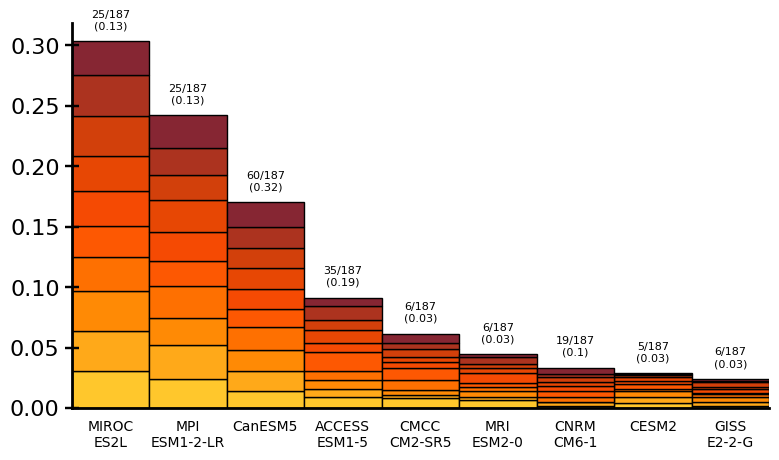

In [18]:
# here is the distribution of how often each model was picked as a top 10 analog
library.plot_model_distribution("BEST-YEARLY", 0, 'tas', 10)

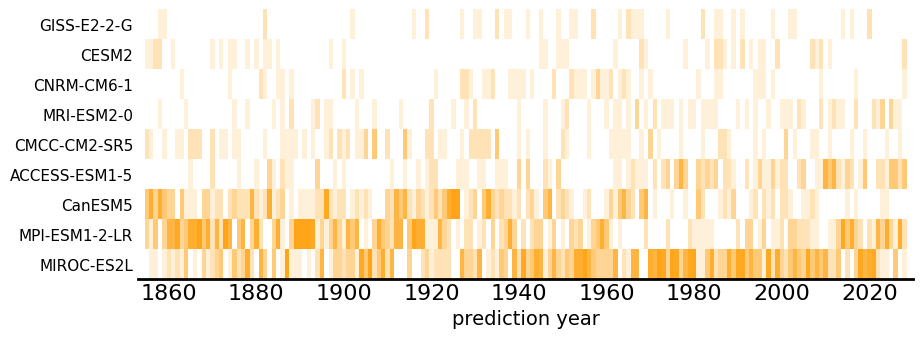

In [19]:
# or plot how often each model is picked as a function of time
library.plot_model_times("BEST-YEARLY", 0, 'tas', 10)

/opt/homebrew/Caskroom/miniforge/base/envs/new_analog/lib/python3.11/site-packages/xarray/core/duck_array_ops.py:188: RuntimeWarning: invalid value encountered in cast
  return data.astype(dtype, **kwargs)


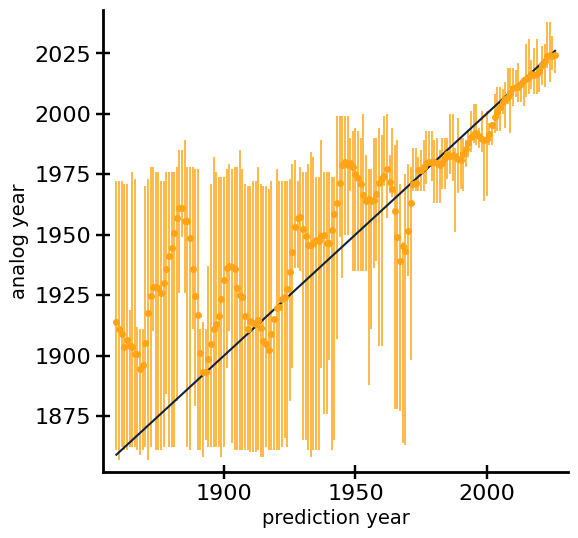

In [44]:
library.plot_selected_times("BEST-YEARLY", 0, 'tas', 10, 5)

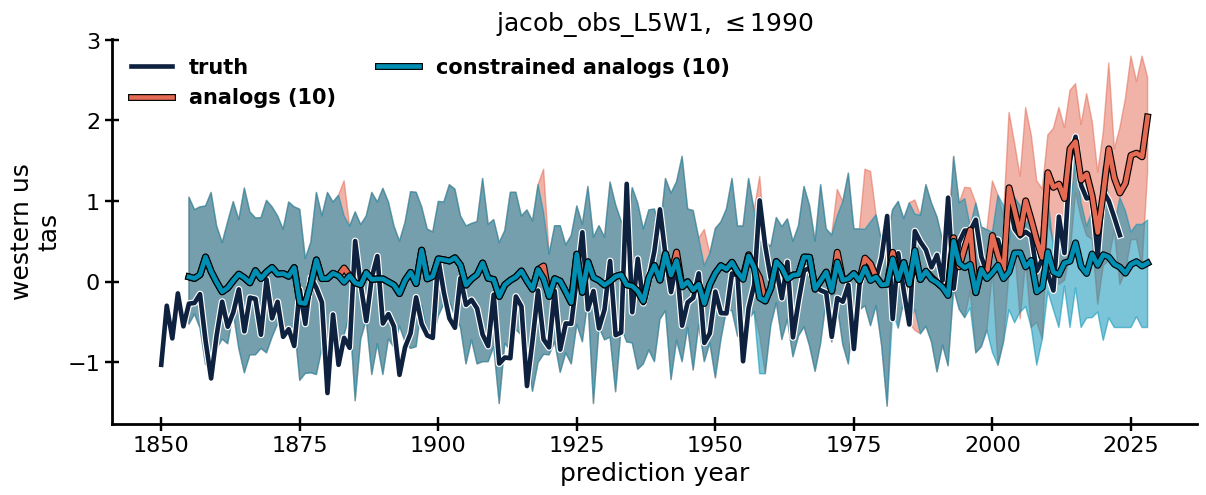

In [22]:
library.plot_constrained_prediction("BEST-YEARLY", 0, 'tas', 10, 1990)